### Imports

In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from tensorflow.keras.models import Sequential
from sklearn.metrics import confusion_matrix

### Paramètres et chargement des données

In [2]:
batch_size = 100
data_dir = 'cats_and_dogs_filtered'

train_tl = tf.keras.utils.image_dataset_from_directory(
    data_dir+"/train",
    validation_split=0.2,
    subset="training",
    seed=342,
    batch_size=batch_size,
    image_size=(224, 224)
)

validation_tl = tf.keras.utils.image_dataset_from_directory(
    data_dir+"/validation",
    seed=342,
    batch_size=batch_size,
    image_size=(224, 224)
)

Found 2000 files belonging to 2 classes.
Using 1600 files for training.
Found 1000 files belonging to 2 classes.


### Construction du modèle (MobileNetV2)

In [3]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,       # enlève la tête de classification ImageNet
    weights="imagenet"
)
base_model.trainable = False   # gèle les poids pré-entraînés

model = Sequential([
    tf.keras.layers.Rescaling(1./127.5, offset=-1, input_shape=(224,224,3)),  # normalisation attendue par MobileNetV2
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


c:\Users\laure\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\preprocessing\data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### Compilation du modèle

In [4]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

### Entraînement

In [5]:
history = model.fit(
    train_tl,
    validation_data=validation_tl,
    epochs=10
)

Epoch 1/10


c:\Users\laure\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


16/16 ━━━━━━━━━━━━━━━━━━━━ 66s 3s/step - accuracy: 0.7600 - loss: 0.4931 - val_accuracy: 0.9630 - val_loss: 0.2319
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 40s 3s/step - accuracy: 0.9550 - loss: 0.1924 - val_accuracy: 0.9800 - val_loss: 0.1170
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 35s 2s/step - accuracy: 0.9737 - loss: 0.1170 - val_accuracy: 0.9840 - val_loss: 0.0843
Epoch 4/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 34s 2s/step - accuracy: 0.9775 - loss: 0.0936 - val_accuracy: 0.9840 - val_loss: 0.0704
Epoch 5/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 33s 2s/step - accuracy: 0.9800 - loss: 0.0793 - val_accuracy: 0.9850 - val_loss: 0.0624
Epoch 6/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 37s 2s/step - accuracy: 0.9812 - loss: 0.0682 - val_accuracy: 0.9860 - val_loss: 0.0570
Epoch 7/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 41s 3s/step - accuracy: 0.9856 - loss: 0.0611 - val_accuracy: 0.9860 - val_loss: 0.0525
Epoch 8/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 41s 3s/step - accuracy: 0.9850 - loss: 0.0595 - val_accuracy: 0.9870 - val_loss: 0.0493
Epo

### Evaluation du test

In [9]:
results = model.evaluate(validation_tl)
print(f"Test Loss: {results[0]:.4f}")
print(f"Test Accuracy: {results[1]:.4f}")

10/10 ━━━━━━━━━━━━━━━━━━━━ 20s 2s/step - accuracy: 0.9870 - loss: 0.0443
Test Loss: 0.0443
Test Accuracy: 0.9870


### Prédictions et matrice de confusion

10/10 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step


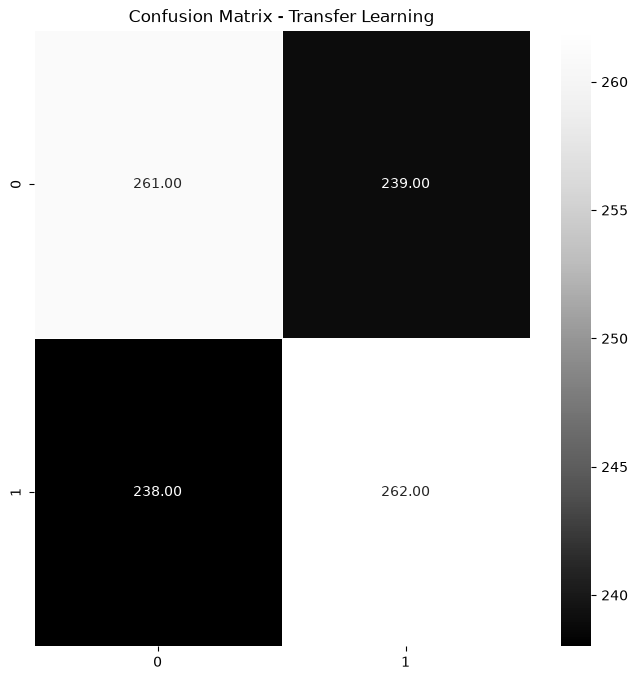

In [10]:
predictions = model.predict(validation_tl)

def to_labels(predictions):
    return [1 if p >= 0.5 else 0 for p in predictions]   # sigmoïde : seuil à 0.5

labels_tl = np.array([])
for images, labels in validation_tl:
    labels_tl = np.append(labels_tl, labels.numpy(), axis=0)

confusionmatrix = confusion_matrix(labels_tl, to_labels(predictions))
plt.figure(figsize=(8,8))
sns.heatmap(confusionmatrix, annot=True, cmap="Greys_r", fmt=".2f", linewidths=0.5)
plt.title("Confusion Matrix - Transfer Learning")
plt.show()